<a href="https://colab.research.google.com/github/rushilnanga/walmart-hurricane-project/blob/main/Final_Walmart_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Question 1

[Clean store_id (stores)] Rebuilt every store_id as FL-### so the files join (2 row(s))
[Store duplicates] Dropped stores listed twice under different ids (FL239, FL_287) (2 row(s))
[Store state] Changed Florida and Fla. to FL (3 row(s))
[Store coordinates] Filled missing lat/lon for FL-619 Tallahassee with city centre coordinates (1 row(s))
[Store timezone] Added tz column: America/Chicago for FL-710 Pensacola, America/New_York for the rest (1 row(s))
[Drop duplicates] Removed exact duplicate rows (0 row(s))
[Clean numbers] Removed $ and commas, changed total_units and total_revenue to float (0 row(s))
[Negative units] Kept rows with negative total_units and flagged them (0 row(s))
[Negative revenue] Kept negative revenue unchanged, kept the units, flagged the row (34 row(s))
[Half units] Kept x.5 unit totals and flagged them (76 row(s))
date
10    3382
8      218
Name: count, dtype: int64
[Parse dates] Rewrote YYYYMMDD dates as YYYY-MM-DD, then converted to datetime (218 row(s))
[Cle

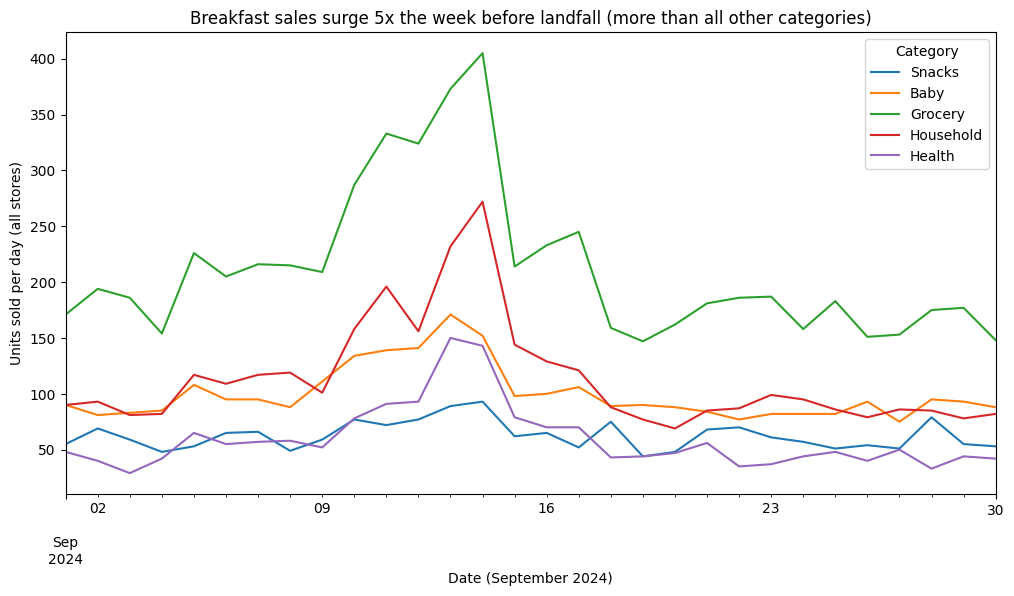

In [ ]:
import os, sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Cleaning
DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')


DB_PATH = 'inventory_and_sales.db'
STORES_PATH = 'store_locations.csv'

# sqlite3.connect() quietly makes an empty database if the file is missing, so check first
assert os.path.exists(DB_PATH), f'{DB_PATH} not found - upload it to the same folder as the notebook'
conn = sqlite3.connect(DB_PATH)

def q(sql):
    return pd.read_sql_query(sql, conn)

sales_raw = q('SELECT * FROM daily_sales_summary')
inventory_raw = q('SELECT * FROM inventory_levels')
stores_raw = pd.read_csv(STORES_PATH)


def drop_duplicates(df):
  'Remove rows that are exact copies of another row'
  out = df.drop_duplicates().reset_index(drop=True)
  log('Drop duplicates', 'Removed exact duplicate rows', len(df) - len(out))
  return out


def clean_numbers(df):
  'Strip $ and commas, then make units and revenue floats'
  out = df.copy()
  affected_rows = 0
  for col in ['total_units', 'total_revenue']:
    affected_rows += out[col].astype(str).str.contains('[$,]', regex=True).sum()
    out[col] = out[col].astype(str).str.replace('[$,]', '', regex=True).astype(float)
  log('Clean numbers', 'Removed $ and commas, changed total_units and total_revenue to float', affected_rows)
  return out


def clean_negatives(df):
  'Negative units, negative revenue, and half units'
  out = df.copy()

  # negative units are returns; keep them so nothing is lost, but flag them
  neg_units = out['total_units'] < 0
  out['neg_units_flag'] = neg_units
  log('Negative units', 'Kept rows with negative total_units and flagged them', neg_units.sum())

  # negative revenue with positive units: keep the value as-is, but flag it
  bad_rev = (out['total_revenue'] < 0) & (out['total_units'] > 0)
  out['revenue_flag'] = bad_rev
  log('Negative revenue', 'Kept negative revenue unchanged, kept the units, flagged the row', bad_rev.sum())

  # you can't sell half an item, but rounding either way would be a guess
  half = out['total_units'] % 1 != 0
  out['half_unit_flag'] = half
  log('Half units', 'Kept x.5 unit totals and flagged them', half.sum())
  return out


def parse_dates(df):
  'The date column has two formats: 2024-09-01 and 20240901'
  out = df.copy()
  print(out['date'].str.len().value_counts())  # 10 = YYYY-MM-DD, 8 = YYYYMMDD
  short = out['date'].str.len() == 8
  d = out.loc[short, 'date']
  out.loc[short, 'date'] = d.str[:4] + '-' + d.str[4:6] + '-' + d.str[6:]
  out['date'] = pd.to_datetime(out['date'], format='%Y-%m-%d')
  log('Parse dates', 'Rewrote YYYYMMDD dates as YYYY-MM-DD, then converted to datetime', short.sum())
  return out


def clean_store_id(df, name):
  'FL239, FL_287, fl 78 -> FL-239, FL-287, FL-078 (keep the digits, rebuild the id)'
  out = df.copy()
  before = out['store_id'].copy()
  digits = out['store_id'].astype(str).str.replace(r'\D', '', regex=True)
  out['store_id'] = 'FL-' + digits.str.zfill(3)
  log(f'Clean store_id ({name})', 'Rebuilt every store_id as FL-### so the files join', (before != out['store_id']).sum())
  return out


def clean_stores(stores):
  'Store file: fix the ids, remove stores listed twice, fix state, coordinates and timezone'
  out = clean_store_id(stores, 'stores')

  rows_before = len(out)
  out = out.drop_duplicates(subset='store_id').reset_index(drop=True)
  log('Store duplicates', 'Dropped stores listed twice under different ids (FL239, FL_287)', rows_before - len(out))

  STATE_MAP = {'Florida': 'FL', 'Fla.': 'FL'}
  changed = out['state'].isin(STATE_MAP.keys()).sum()
  out['state'] = out['state'].map(STATE_MAP).fillna(out['state'])
  out['region'] = out['region'].str.strip()
  log('Store state', 'Changed Florida and Fla. to FL', changed)

  # Tallahassee has no coordinates and the weather API needs them, so I used the city centre
  missing = out['latitude'].isna().sum()
  out.loc[out['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]
  log('Store coordinates', 'Filled missing lat/lon for FL-619 Tallahassee with city centre coordinates', missing)

  # Pensacola is on Central time, every other store is Eastern (needed to line up the weather)
  out['tz'] = np.where(out['store_id'] == 'FL-710', 'America/Chicago', 'America/New_York')
  log('Store timezone', 'Added tz column: America/Chicago for FL-710 Pensacola, America/New_York for the rest',
      (out['tz'] == 'America/Chicago').sum())
  return out


def clean_sales(df):
  'Run every sales cleaning step in order'
  out = drop_duplicates(df)
  out = clean_numbers(out)
  out = clean_negatives(out)
  out = parse_dates(out)
  out = clean_store_id(out, 'sales')
  return out


stores = clean_stores(stores_raw)
sales = clean_sales(sales_raw)

print()
print(f'Rows before cleaning: {len(sales_raw)}')
print(f'Rows after cleaning: {len(sales)}')
print(f'Rows removed: {len(sales_raw) - len(sales)}')
print(f'Store file: {len(stores_raw)} rows before, {len(stores)} rows after')
sales.head(10)

# Demand Surge

# TODO: the numbers
tx = pd.read_csv('/content/walmart_transactions.csv').drop_duplicates()
tx = tx[tx['quantity'] > 0].copy()
tx['date'] = pd.to_datetime(tx['timestamp'], errors='coerce', format='mixed').dt.normalize()

#category labels (18)
CATEGORY_MAP = {
    'Alcoholic Beverages': 'Alcohol',
    'Baby Products': 'Baby',
    'Breakfast Foods': 'Breakfast',
    'Emergency Supplies': 'Emergency',
    'Games & Entertainment': 'Entertainment',
    'Groceries': 'Grocery',
    'Health & Wellness': 'Health',
    'Household Essentials': 'Household',
    }

before = tx['category'].nunique()
tx['category'] = tx['category'].str.strip().str.title().replace(CATEGORY_MAP)
log('Category labels', 'Strip, title-case, merge duplicate category names', before-tx['category'].nunique())

#windows: daily volume peaks at Sept 24-25 and drops after Sept 26
BASELINE = ('2024-09-01', '2024-09-15')
SURGE = ('2024-09-19', '2024-09-25')

daily_cat = tx.groupby(['date', 'category'])['quantity'].sum().unstack()

q1 = pd.DataFrame({
    'baseline_avg': daily_cat.loc[BASELINE[0]:BASELINE[1]].mean(),
    'surge_avg': daily_cat.loc[SURGE[0]:SURGE[1]].mean(),
})

q1['multiple'] = q1['surge_avg'] / q1['baseline_avg']
q1 ['pct_increase'] = (q1['multiple'] - 1) * 100
q1 = q1.sort_values('multiple', ascending=False)

print('Baseline window:', BASELINE[0], 'to' , BASELINE[1])
print('Surge window:', SURGE[0], 'to' , SURGE[1])
print('Rows with no timestamp (not in any window)', tx['date'].isna().sum())
q1.round(2)

# Chart
top5 = q1.index[:5]
daily_cat[top5].plot(figsize=(12, 6))
plt.title('Breakfast sales surge 5x the week before landfall (more than all other categories)')
plt.xlabel('Date (September 2024)')
plt.ylabel('Units sold per day (all stores)')
plt.legend(title='Category')
plt.show()

Which product categories experienced the greatest sales surge in the 7 days before hurricane landfall compared to the prior baseline period? Quantify the percentage increase and visualize the daily trend for the top 5 categories.

Question 2

[SKU consolidation] Mapped variant SKUs to one canonical SKU per product (25 row(s))
Starting SKUs 45
canonical products: 20
largest family: POPTART-STRAW (4 SKUs)


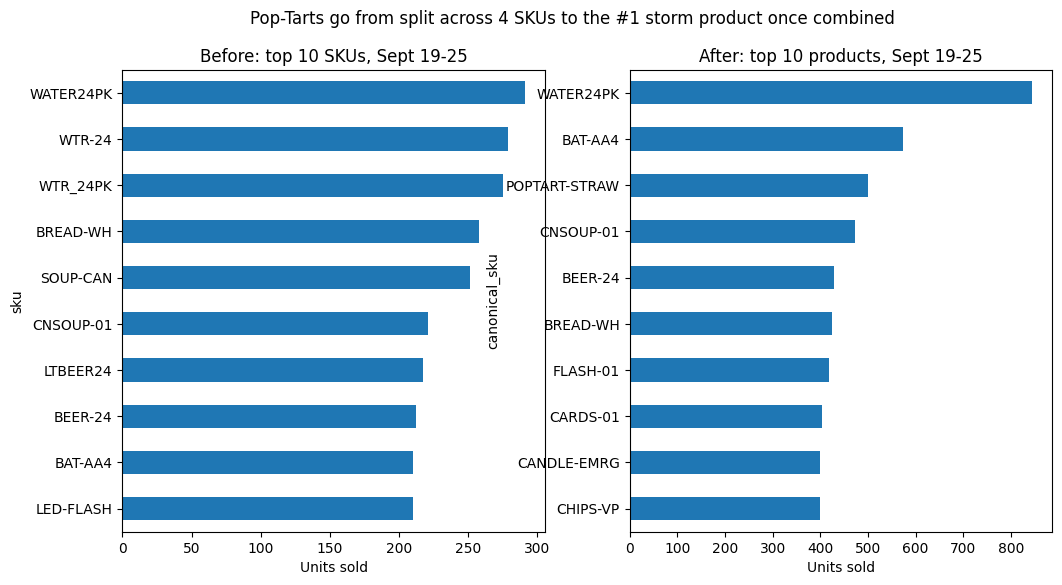

In [ ]:
# TODO
SKU_MAP = {
     'POPTART-STRAW': ['POPTART-STRAW', 'PT-12', 'PT_STRAWBERRY', 'SKU#459812'],
    'WATER24PK': ['WATER24PK', 'WTR-24', 'WTR_24PK'],
    'BAT-AA4': ['BAT-AA4', 'BATT-100', 'BATT_AA_4PK'],
    'BG-MONO': ['BG-MONO', 'GAME-MONO', 'MONOPOLY-01'],
    'FLASH-01': ['FLASH-01', 'LED-FLASH'], 'BEER-24': ['BEER-24', 'LTBEER24'],
    'CARDS-01': ['CARDS-01', 'PLAYCARD-STD'], 'ROKU-STD': ['ROKU-STD', 'STREAM-01'],
    'CNSOUP-01': ['CNSOUP-01', 'SOUP-CAN'], 'BREAD-WH': ['BREAD-WH', 'WHITEBREAD'],
    'PB-16': ['PB-16', 'PNUTBTR-16'], 'CANDLE-EMRG': ['CANDLE-EMRG', 'CNDL-EM'],
    'FAID-01': ['FAID-01', 'FIRSTAID-KIT'], 'CHRG-PORT': ['CHRG-PORT', 'PORTCHARGER'],
    'CHIPS-VP': ['CHIPS-VP', 'CHIPVARIETY'], 'PAPERTOWEL6': ['PAPERTOWEL6', 'PTOWEL-6'],
    'TOILETPAPER12': ['TOILETPAPER12', 'TP-12'], 'DIAP-S3': ['DIAP-S3', 'DIAPERS-3'],
    'BABYFORMULA': ['BABYFORMULA', 'BFORM-01'], 'HDTARP-01': ['HDTARP-01', 'TARP-HD'],
}

variant_to_canonical = {}
for canonical, variants in SKU_MAP.items():
    for variant in variants:
        variant_to_canonical[variant] = canonical

tx['canonical_sku'] = tx['sku'].map(variant_to_canonical).fillna(tx['sku'])
log('SKU consolidation', 'Mapped variant SKUs to one canonical SKU per product', tx['sku'].nunique()-tx['canonical_sku'].nunique())

assert tx['canonical_sku'].notna().all()
assert tx.groupby('canonical_sku')['quantity'].sum().sum() == tx['quantity'].sum()

sizes = tx.groupby('canonical_sku')['sku'].nunique()
print('Starting SKUs', tx['sku'].nunique())
print('canonical products:', tx['canonical_sku'].nunique())
print('largest family:', sizes.idxmax(), f'({sizes.max()} SKUs)')

#before vs after for Pop-Tarts (q1 window)
daily_sku = tx.groupby(['date', 'sku'])['quantity'].sum().unstack(fill_value=0)
pt = daily_sku[SKU_MAP['POPTART-STRAW']]
cmp = pd.DataFrame({'baseline_avg': pt.loc[BASELINE[0]:BASELINE[1]].mean(),
                    'surge_avg': pt.loc[SURGE[0]:SURGE[1]].mean()})
cmp.loc['All 4 COMBINED'] = [pt.sum(axis=1).loc[BASELINE[0]:BASELINE[1]].mean(),
                        pt.sum(axis=1).loc[SURGE[0]:SURGE[1]].mean()]

cmp.round(1)

# Chart
in_surge = tx['date'].between(*SURGE)
surge_sku = tx[in_surge].groupby('sku')['quantity'].sum().nlargest(10).sort_values()
surge_prod = tx[in_surge].groupby('canonical_sku')['quantity'].sum().nlargest(10).sort_values()

fig, axes = plt.subplots(1,2,figsize=(12,6))
surge_sku.plot.barh(ax=axes[0], title='Before: top 10 SKUs, Sept 19-25')
surge_prod.plot.barh(ax=axes[1], title='After: top 10 products, Sept 19-25')
axes[0].set_xlabel("Units sold")
axes[1].set_xlabel("Units sold")
fig.suptitle('Pop-Tarts go from split across 4 SKUs to the #1 storm product once combined')
plt.show()


After standardizing all Pop-Tart SKU variants into a single product, what is the true daily sales volume? How does the uncleaned (fragmented) view compare to the cleaned (consolidated) view? What business decisions would differ between the two views?

The true daily volume for Pop-Tarts, after consolidating the 4 Pop-Tart SKUs into one product, was about 73 units sold per day in the baseline (Sept 1-15) and about 377 units/day in the 7 days before landfall (Sept 19-25). This represents a 5.1x increase.

When looking at each SKU fragmented on its own, each had about 17-20/day at the baseline and 90-103/day during the surge. The highest single Pop-Tart SKU ranked 3rd in the surge week, behind 2 water SKUs. When consolidated, Pop-Tarts became the top product in the surge week.

A few business decisions would differ depending on these two views. First, in the fragmented view, the largest selling Pop-Tart SKU averages about 103 units/day during the surge, but consolidated, true Pop-Tart demand is about 377 units/day, more than 3.5x any single SKU. As a result, ordering based on the fragmented view would plan for much less than the actual demand for Pop-Tarts. Secondly, if products are restocked based on sales, the fragmented view puts 2 water SKUs ahead of all Pop-Tart SKUs, so Pop-Tarts would be restocked after water. The consolidated view shows Pop-Tarts was the top product for the surge week, therefore, it should be restocked first. Lastly, no single Pop-Tart SKU is in the top seller fort eh fragmented view, but together, Pop-Tarts rise to the top in the consolidated view. Without consolidating, it would be easy to fail to recognize Pop-Tarts as a storm product.

Question 3

In [ ]:
import requests
import time
import seaborn as sns

# weather data from Open-Meteo
def get_weather(lat, lon, timezone):
    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": "2024-09-01",
        "end_date": "2024-09-30",
        "daily": "precipitation_sum,wind_speed_10m_max,pressure_msl_mean",
        "timezone": timezone
    }

    for attempt in range(3):
        try:
            response = requests.get(url, params=params, timeout=20)
            response.raise_for_status()
            data = response.json()["daily"]

            return pd.DataFrame({
                "date": pd.to_datetime(data["time"]),
                "precipitation": data["precipitation_sum"],
                "wind_speed": data["wind_speed_10m_max"],
                "pressure": data["pressure_msl_mean"]
            })

        except (requests.RequestException, KeyError, ValueError):
            if attempt == 2:
                raise
            time.sleep(2)

# weather for each store
weather_list = []

for _, store in stores.iterrows():
    w = get_weather(
        store["latitude"],
        store["longitude"],
        store["tz"]
    )
    w["store_id"] = store["store_id"]
    weather_list.append(w)

weather = pd.concat(weather_list, ignore_index=True)

# daily sales by store and category
sales_q3 = tx.dropna(subset=["date"]).copy()

sales_q3["store_id"] = (
    "FL-" +
    sales_q3["store_id"].astype(str)
    .str.replace(r"\D", "", regex=True)
    .str.zfill(3)
)

daily_sales = (
    sales_q3.groupby(["store_id", "date", "category"], as_index=False)
    ["quantity"].sum()
)

# join sales with weather
before = len(daily_sales)

joined = daily_sales.merge(
    weather,
    on=["store_id", "date"],
    how="left",
    validate="many_to_one"
)

after = len(joined)
q3_join_rows_preserved = before == after

assert q3_join_rows_preserved

print("Rows before join:", before)
print("Rows after join:", after)
print("Rows preserved:", q3_join_rows_preserved)
print("Missing weather rows:", joined["wind_speed"].isna().sum())
print("Weather source: Live Open-Meteo API request (historical data)")
print("Fallback used: No")

# correlations - weather/stores

daily_weather = (
    weather.groupby("date")
    [["precipitation", "wind_speed", "pressure"]]
    .mean()
)

daily_categories = (
    joined.groupby(["date", "category"])["quantity"]
    .sum()
    .unstack(fill_value=0)
)

combined = daily_categories.join(daily_weather, how="inner").dropna()

q3_days_in_correlation = len(combined)

weather_cols = ["precipitation", "wind_speed", "pressure"]
category_cols = daily_categories.columns.tolist()

correlations = combined.corr().loc[category_cols, weather_cols]

print("\nDays used for correlation:", q3_days_in_correlation)
print("\nWeather correlations by category:")
print(correlations.round(2))

# correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Relationships Between Weather Indicators and Walmart Sales")
plt.xlabel("Weather Indicator")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

# correlation for each category
lag_results = []

for category in category_cols:
    for indicator in weather_cols:
        for lag in range(-3, 4):

            correlation = combined[category].corr(
                combined[indicator].shift(lag)
            )

            lag_results.append({
                "category": category,
                "weather_indicator": indicator,
                "lag_days": lag,
                "correlation": correlation
            })

lag_df = pd.DataFrame(lag_results)

best_lags = (
    lag_df.dropna(subset=["correlation"])
    .assign(abs_corr=lambda x: x["correlation"].abs())
    .sort_values("abs_corr", ascending=False)
    .drop_duplicates("category")
    .drop(columns="abs_corr")
    .sort_values("category")
)

print("Strongest weather-sales lag correlation by category:")
print(best_lags.round(2).to_string(index=False))

HTTPError: 503 Server Error: Service Unavailable for url: https://archive-api.open-meteo.com/v1/archive?latitude=28.5383&longitude=-81.3792&start_date=2024-09-01&end_date=2024-09-30&daily=precipitation_sum%2Cwind_speed_10m_max%2Cpressure_msl_mean&timezone=America%2FNew_York

Using weather data pulled from your chosen free API, how do specific weather indicators (wind speed, precipitation, barometric pressure) correlate with daily sales volume across categories? Is there a detectable lag between weather severity escalation and purchasing spikes?

Question 4

Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.

Question 5

The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?